In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
print(sys.path[0])

/home/benjamin-rodriguez/Desktop/PredictionMarkets


In [43]:
from analysis.time_series import ( 
    to_logit, from_logit, plot_price_and_logit, adf_report, adf_summary ,
    plot_acf_pacf, lag1_autocorr_distribution, plot_lag1_distribution, has_real_movement,
    rank_by_predictability, compare_ar_orders, ar_order_survey, acf, reversion_vs_spread, 
    autocorr_vs_frequency, add_logit, logit_diffs, plot_volatility, plot_volatility_colored, rolling_volatility
)
from analysis.microstructure import filter_liquid_markets, add_relative_spread
from analysis.filters import drop_post_resolution, filter_consistently_active
from db.load import load_movers
from db.connection import get_engine
import numpy as np
import pandas as pd


x = np.linspace(0, 1, 50)
print(f"to_logit({x}) = {to_logit(x)}")

to_logit([0.         0.02040816 0.04081633 0.06122449 0.08163265 0.10204082
 0.12244898 0.14285714 0.16326531 0.18367347 0.20408163 0.2244898
 0.24489796 0.26530612 0.28571429 0.30612245 0.32653061 0.34693878
 0.36734694 0.3877551  0.40816327 0.42857143 0.44897959 0.46938776
 0.48979592 0.51020408 0.53061224 0.55102041 0.57142857 0.59183673
 0.6122449  0.63265306 0.65306122 0.67346939 0.69387755 0.71428571
 0.73469388 0.75510204 0.7755102  0.79591837 0.81632653 0.83673469
 0.85714286 0.87755102 0.89795918 0.91836735 0.93877551 0.95918367
 0.97959184 1.        ]) = [-23.02585093  -3.87120101  -3.15700042  -2.73002911  -2.42036813
  -2.17475172  -1.96944065  -1.79175947  -1.63413053  -1.49165488
  -1.36097655  -1.23969089  -1.12601126  -1.01856958  -0.91629073
  -0.81831032  -0.72391884  -0.63252256  -0.54361545  -0.4567584
  -0.37156356  -0.28768207  -0.20479441  -0.12260232  -0.04082199
   0.04082199   0.12260232   0.20479441   0.28768207   0.37156356
   0.4567584    0.54361545   0.632

In [20]:
# 3.1 — see the transform
df = load_movers(min_range=0.2)
df = drop_post_resolution(df)
df = add_relative_spread(df)
df = filter_liquid_markets(df, keep_tiers=("tight", "medium"))

[post-resolution] dropped 9969 rows at/after resolution
[liquidity] 4298 markets -> 600 in tiers ['medium', 'tight'] (3698 dropped)
relative_spread
untradeable    3324
medium          380
wide            374
tight           220


In [ ]:
df = filter_consistently_active(df, percent_move_threshold=.50, median_move_threshold=-0.0001)
df = add_logit(df)

[filter_consistently_active] dropped 20 markets not consistently active


In [47]:
ids = set(df["market_id"])

print(ids)

{'907604', '676741', '1897148', '558938', '2109512', '1185734', '1897188', '2071552', '2834884', '908713', '558934', '1284065', '1283472', '1654959', '942886', '701702', '2252245', '1494696', '1846836', '1897155', '2089026', '904393', '943003', '839429', '1897254', '2676740', '678447', '1897146', '2373683', '944342', '2087972', '558936', '1285422', '1735279', '1897168', '1383905', '2087973', '2071546', '2118145', '2961603', '943571', '1280800', '1571989', '1283985', '679608', '1546000', '2950652', '1287622', '839436', '1652706', '2325387', '1283480', '704280', '1283160', '2771185', '599304', '1897123', '973439', '1732104', '799453', '2154786', '695085', '943579', '2698250', '734890', '1897331', '1897445', '1795635', '2046235', '1897355', '1284420', '942325', '1285421', '2244712', '1032424', '1284331', '1163699', '2069847', '840931', '2744159', '1281165', '665531', '942409', '1282953', '1284074', '907358', '907513', '1822536', '630772', '897019', '839397', '942885', '839959', '1897177',

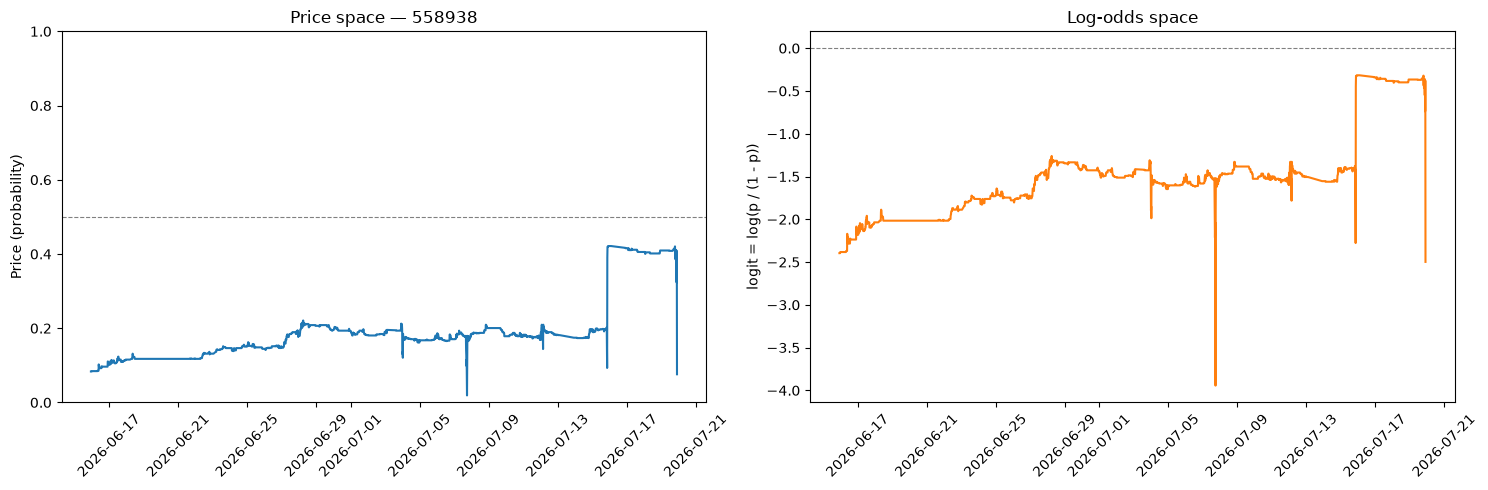

2915 snapshots, price range [0.019, 0.421]


In [51]:
one = df[df["market_id"] == "558938"]
plot_price_and_logit(one)

In [52]:
def find_name(market_ids: list[str]) -> pd.DataFrame:
    """
    Find markets whose price ranged widely (dipped below `lo` and rose above `hi`),
    with at least min_snaps snapshots. Useful for picking demo markets where the
    logit stretch is visually obvious.
    """
    from db.connection import get_conn
    sql = """
        SELECT title
        FROM markets
        WHERE market_id = ANY(%s)
    """
    with get_conn() as conn:
        return pd.read_sql(sql, conn, params=(market_ids,))
    
print(find_name(["558938"]))

                                         title
0  Will Argentina win the 2026 FIFA World Cup?


/tmp/ipykernel_81925/619418748.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(sql, conn, params=(market_ids,))


In [26]:
# 3.2 — stationarity on one market
adf_report(one)


ADF test — market 1005343  (4976 snapshots)
  log-odds LEVELS:
    ADF stat = -0.441   p = 0.9031   -> non-stationary (5% level)
    lags = 7, n = 4968
  log-odds FIRST DIFFERENCES:
    ADF stat = -35.277   p = 0.0000   -> STATIONARY (5% level)
    lags = 6, n = 4968


In [29]:
# 3.2 — confirm the pattern holds across many
adf_summary(df)

/home/benjamin-rodriguez/miniconda3/envs/pred/lib/python3.12/site-packages/statsmodels/regression/linear_model.py:955: RuntimeWarning: divide by zero encountered in log
  llf = -nobs2*np.log(2*np.pi) - nobs2*np.log(ssr / nobs) - nobs2
/home/benjamin-rodriguez/miniconda3/envs/pred/lib/python3.12/site-packages/statsmodels/regression/linear_model.py:955: RuntimeWarning: divide by zero encountered in log
  llf = -nobs2*np.log(2*np.pi) - nobs2*np.log(ssr / nobs) - nobs2
/home/benjamin-rodriguez/miniconda3/envs/pred/lib/python3.12/site-packages/statsmodels/regression/linear_model.py:955: RuntimeWarning: divide by zero encountered in log
  llf = -nobs2*np.log(2*np.pi) - nobs2*np.log(ssr / nobs) - nobs2
/home/benjamin-rodriguez/miniconda3/envs/pred/lib/python3.12/site-packages/statsmodels/regression/linear_model.py:955: RuntimeWarning: divide by zero encountered in log
  llf = -nobs2*np.log(2*np.pi) - nobs2*np.log(ssr / nobs) - nobs2
/home/benjamin-rodriguez/miniconda3/envs/pred/lib/python3.12

580 markets tested
  levels stationary:      21.6%
  differences stationary: 88.8%
  (expect: levels mostly NON-stationary, differences mostly stationary)


,market_id,n,levels_stationary,diffs_stationary
0,1005343,4976,False,True
1,1006908,4965,False,True
2,1032424,1365,True,True
3,1066081,702,False,True
4,1068307,4976,False,True
...,...,...,...,...
575,973389,552,False,True
576,973439,698,False,True
577,973441,710,False,True
578,973624,4976,False,True


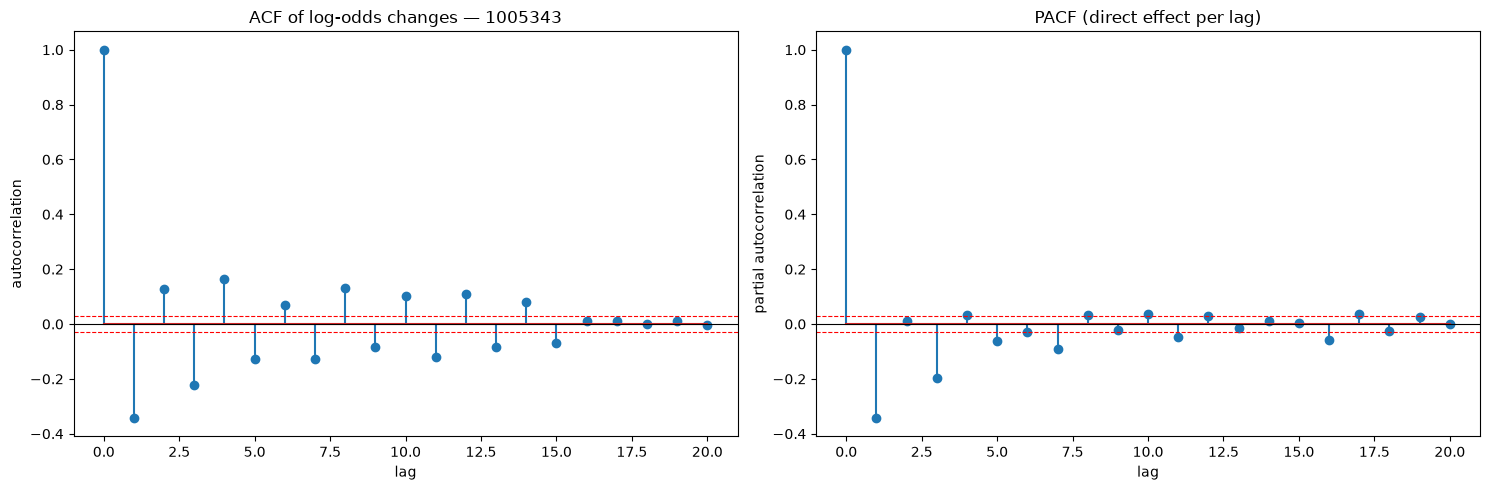

n=4975 changes, significance band = +/- 0.028
lag-1 ACF = -0.343   lag-1 PACF = -0.343
580 markets
  mean lag-1 ACF   = -0.0452
  median lag-1 ACF = -0.0620
  fraction positive = 32.4%
  fraction significantly positive (>+0.031) = 24.7%  [momentum]
  fraction significantly negative (<-0.031) = 58.3%  [reversion / bounce]
  NOTE: short-lag negative autocorr may be bid-ask bounce, untradeable.


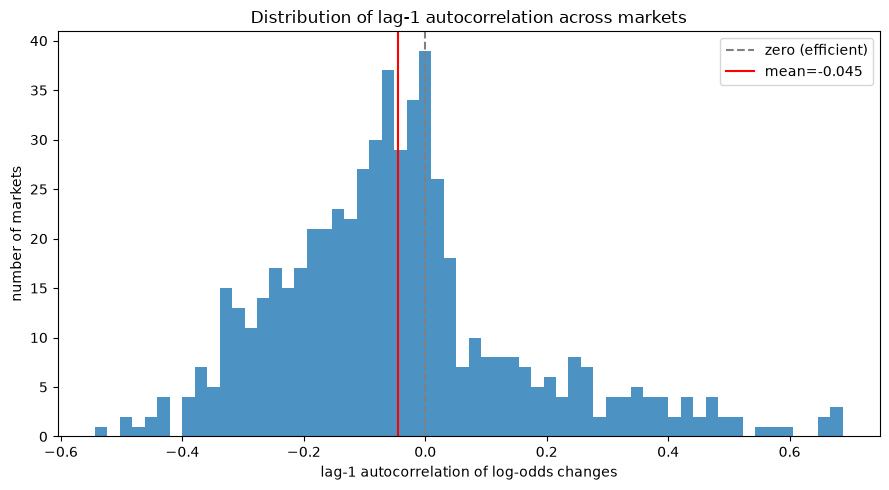

In [28]:
# 3.3 — visual on one market, then the aggregate
plot_acf_pacf(one)
dist = lag1_autocorr_distribution(df)
plot_lag1_distribution(dist)

In [30]:
# 3.4 — rank by predictability
ranked = rank_by_predictability(df)
print(ranked.head(20))

580 markets fit
  significant AR(1): 79.0%
  mean phi (all):        -0.0084
  mean phi (significant): -0.0108
  phi>0 momentum, phi<0 mean reversion (or bounce)
       n       phi        p_value  significant market_id   abs_phi
227  783 -3.641269   7.468000e-24         True   1897433  3.641269
167  137 -3.494446  2.448743e-138         True   1897148  3.494446
230  782 -3.382062   0.000000e+00         True   1897438  3.382062
175  250  3.232176   0.000000e+00         True   1897187  3.232176
234  793 -2.679255   0.000000e+00         True   1897444  2.679255
207  606  2.601992   1.023489e-95         True   1897348  2.601992
180  337 -2.565637  1.239135e-165         True   1897221  2.565637
216  691  2.551953   0.000000e+00         True   1897381  2.551953
179  332  2.466468   3.226133e-07         True   1897213  2.466468
186  427 -2.371102   2.088681e-55         True   1897255  2.371102
202  594  2.368683   0.000000e+00         True   1897330  2.368683
209  606  2.320764  1.968479e-192  

In [31]:
# does ar(1) suffice, or do markets need more?
best_order = ar_order_survey(df)

print(best_order.std())

/home/benjamin-rodriguez/miniconda3/envs/pred/lib/python3.12/site-packages/statsmodels/tsa/ar_model.py:517: RuntimeWarning: divide by zero encountered in log
  llf = -(nobs / 2) * (np.log(2 * np.pi) + np.log(ssr / nobs) + 1)
/home/benjamin-rodriguez/miniconda3/envs/pred/lib/python3.12/site-packages/statsmodels/tsa/ar_model.py:517: RuntimeWarning: divide by zero encountered in log
  llf = -(nobs / 2) * (np.log(2 * np.pi) + np.log(ssr / nobs) + 1)
/home/benjamin-rodriguez/miniconda3/envs/pred/lib/python3.12/site-packages/statsmodels/tsa/ar_model.py:517: RuntimeWarning: divide by zero encountered in log
  llf = -(nobs / 2) * (np.log(2 * np.pi) + np.log(ssr / nobs) + 1)
/home/benjamin-rodriguez/miniconda3/envs/pred/lib/python3.12/site-packages/statsmodels/tsa/ar_model.py:517: RuntimeWarning: divide by zero encountered in log
  llf = -(nobs / 2) * (np.log(2 * np.pi) + np.log(ssr / nobs) + 1)
/home/benjamin-rodriguez/miniconda3/envs/pred/lib/python3.12/site-packages/statsmodels/tsa/ar_model.

580 markets surveyed
BIC-preferred AR order distribution:
best_bic_order
1    30.7
2    11.7
3    11.9
4    16.4
5    29.3
1.638689911935448


In [ ]:
# Is what we are seeing spread bounce or mean reversion
for time in ["1h", "2h", "4h", "12h", "24h"]:
    print(f"Sampled every {time}:")
    rv = reversion_vs_spread(df, sampling_freq=time)

Sampled every 1h:
247 markets with events
  mean profit per trade (avg over markets): -0.1089
  fraction of markets with positive mean profit: 8.5%
Sampled every 2h:
223 markets with events
  mean profit per trade (avg over markets): -0.1065
  fraction of markets with positive mean profit: 6.3%
Sampled every 4h:
205 markets with events
  mean profit per trade (avg over markets): -0.1042
  fraction of markets with positive mean profit: 5.9%
Sampled every 12h:
127 markets with events
  mean profit per trade (avg over markets): -0.0607
  fraction of markets with positive mean profit: 22.0%
Sampled every 24h:
58 markets with events
  mean profit per trade (avg over markets): -0.0307
  fraction of markets with positive mean profit: 31.0%


In [38]:
# Do the numbers change if we look at different frequencies?
freq = autocorr_vs_frequency(df, freqs=["30min", "1h", "2h", "4h", "8h", "1d", "2d", "4d"])

580 markets — mean lag-1 autocorrelation by sampling frequency:
   30min: mean = -0.0504   (n=580)
      1h: mean = -0.0400   (n=580)
      2h: mean = -0.0604   (n=568)
      4h: mean = -0.0898   (n=557)
      8h: mean = -0.1119   (n=520)
      1d: mean = -0.0968   (n=393)
      2d: mean = -0.1120   (n=341)
      4d: mean = +nan   (n=0)
  -> If it moves toward 0 as frequency coarsens, it's bid-ask bounce.
  -> If it stays strongly negative at the coarsest, it may be real.


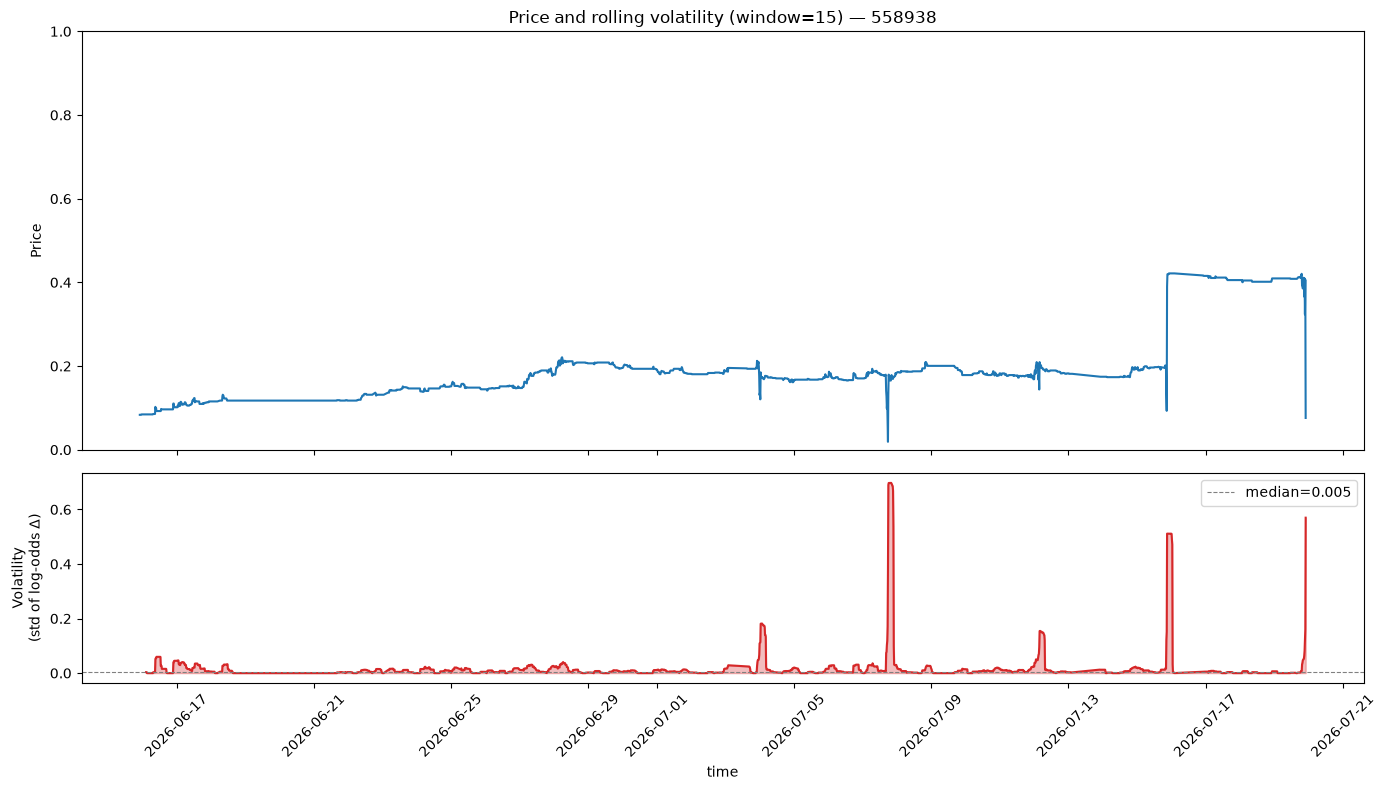

In [ ]:
# one currently is will argentina win the world cup: you can see dips are: Playing cabo verde, playing and going down 0-2 to egypt, playing switzerland, playing england, and losing to spain respectively from left to right

plot_volatility(one)

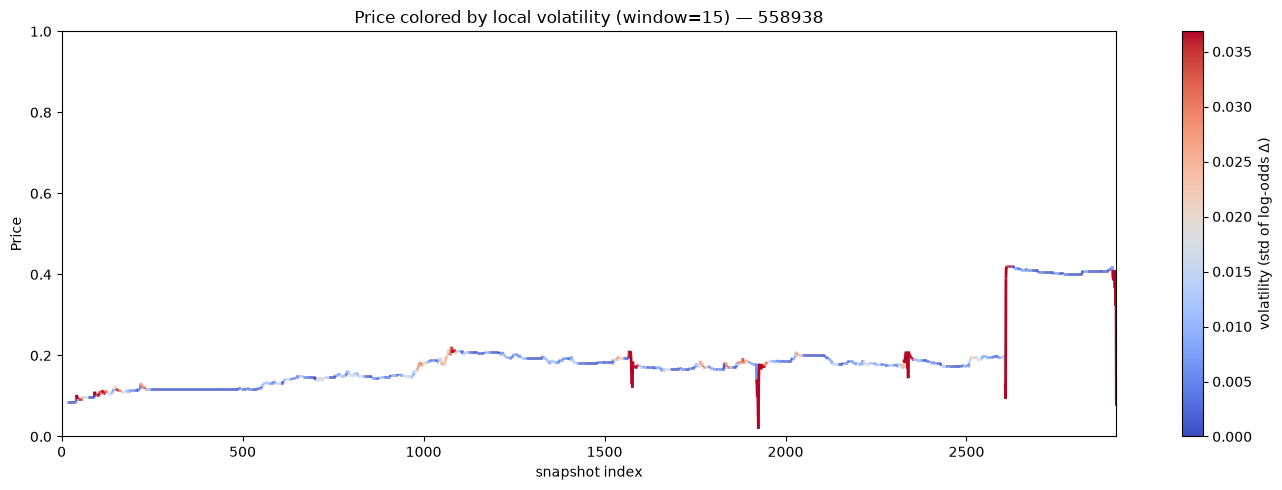

In [54]:
plot_volatility_colored(one)